In [2]:
import mirdata

ballroom = mirdata.initialize('ballroom')
ballroom.download()
ballroom.validate()
track_ids = ballroom.track_ids

In [64]:
len(track_ids)

698

In [56]:
import pandas as pd

dataset_df = pd.DataFrame(columns=["track name", "track_style", "bpm", "metre"])

for i, track_id in enumerate(track_ids):
    track = ballroom.track(track_id)
    split_path = track.audio_path.split("/")
    track_name = split_path[-1]
    track_style = split_path[-2]
    metre = max(track.beats.positions)
    bpm = track.tempo
    
    dataset_df.loc[i] = [track_name, track_style, bpm, metre]

dataset_df.head()

,track name,track_style,bpm,metre
0,Media-105901.wav,Waltz,84.0,3
1,Albums-Step_By_Step-04.wav,Waltz,87.0,3
2,Media-104202.wav,Waltz,87.0,3
3,Media-104203.wav,Waltz,87.0,3
4,Media-105902.wav,Waltz,84.0,3


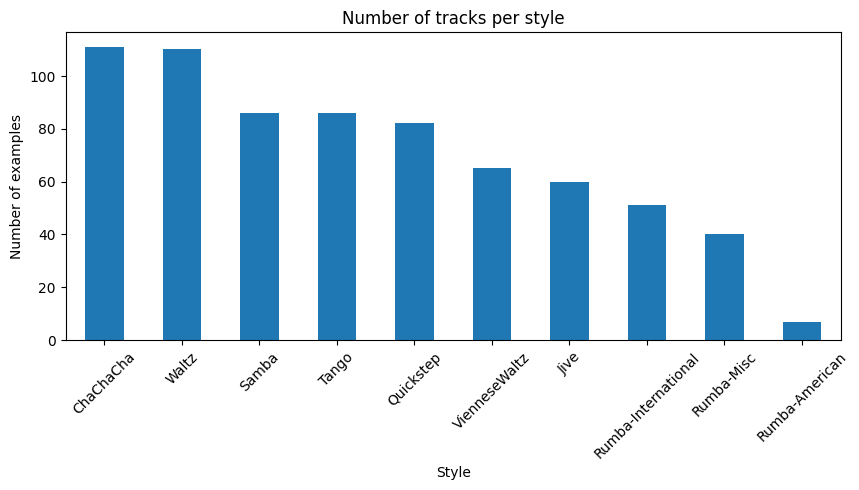

In [57]:
style_counts = dataset_df["track_style"].value_counts().sort_values(ascending=False)

ax = style_counts.plot(kind="bar", figsize=(10, 4), title="Number of tracks per style")
ax.set_xlabel("Style")
ax.set_ylabel("Number of examples")
ax.tick_params(axis="x", rotation=45)

INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


Text(0, 0.5, 'Count')

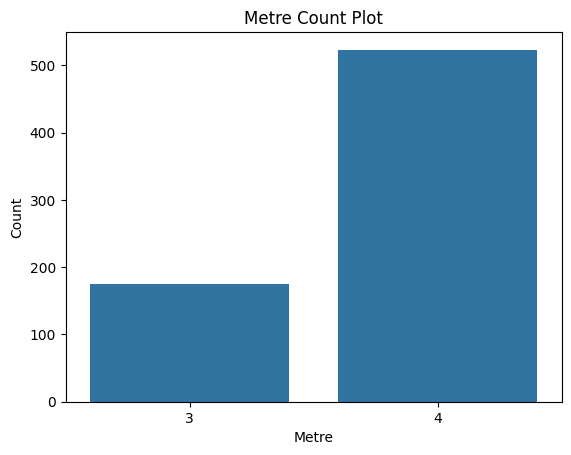

In [ ]:
import seaborn as sns

metre_ax = sns.countplot(data=dataset_df, x="metre")

metre_ax.set_title("Metre Count Plot")
metre_ax.set_xlabel("Metre")
metre_ax.set_ylabel("Count")

Text(0, 0.5, 'Count')

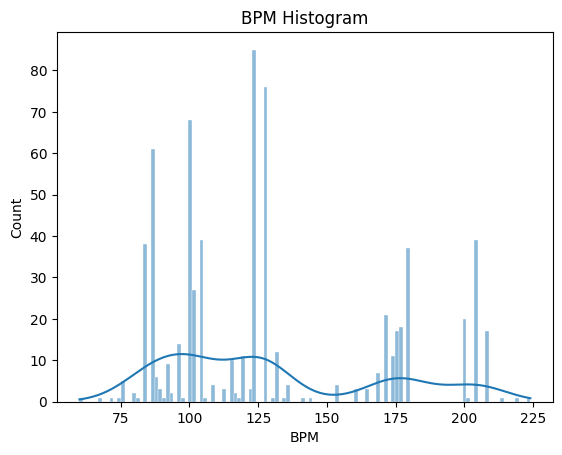

In [ ]:
bpm_ax = sns.histplot(data=dataset_df, x="bpm", kde=True, bins=120, edgecolor="white")
bpm_ax.set_title("BPM Histogram")
bpm_ax.set_xlabel("BPM")
bpm_ax.set_ylabel("Count")

Text(0.5, 1.0, 'BPM Distribution by Style')

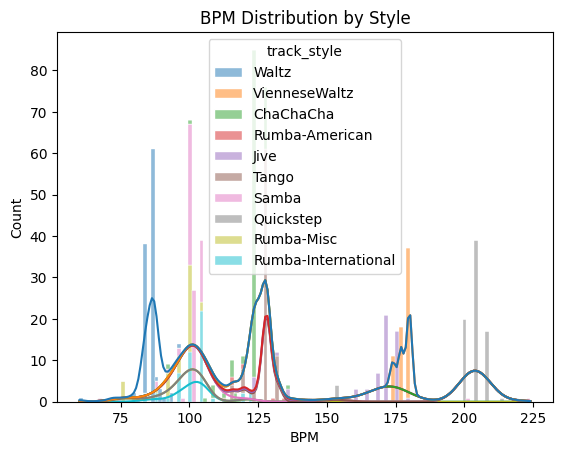

In [ ]:
hist_ax = sns.histplot(
    data=dataset_df,
    x="bpm",
    hue="track_style",
    kde=True,
    bins=120,
    multiple="stack",   # one histogram, stacked by style
    edgecolor="white"
)

hist_ax.set_xlabel("BPM")
hist_ax.set_ylabel("Count")
hist_ax.set_title("BPM Distribution by Style")


Text(0.5, 1.0, 'BPM Distribution by Metre')

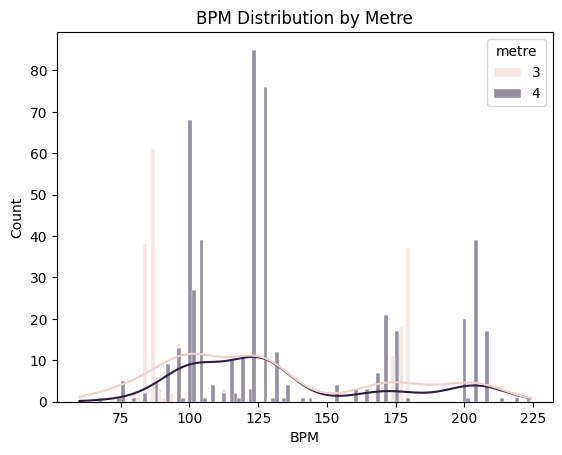

In [63]:
hist_ax = sns.histplot(
    data=dataset_df,
    x="bpm",
    hue="metre",
    kde=True,
    bins=120,
    multiple="stack",   # one histogram, stacked by style
    edgecolor="white"
)

hist_ax.set_xlabel("BPM")
hist_ax.set_ylabel("Count")
hist_ax.set_title("BPM Distribution by Metre")
